# Random Forest: previsão de compra (Revenue)

Este notebook usa os scripts compartilhados do grupo (`preprocessamento.py` e `avaliacao.py`).
Execute este notebook a partir da raiz do projeto ou da pasta `script`.

## 1) Imports

In [ ]:
import sys
from pathlib import Path

raiz = Path.cwd().resolve()
if not (raiz / "src" / "preprocessamento.py").is_file():
    raiz = raiz.parent
if not (raiz / "src" / "preprocessamento.py").is_file():
    raise FileNotFoundError("Execute a partir da raiz do projeto ou da pasta script.")
saida = raiz / "resultados"
saida.mkdir(exist_ok=True)
sys.path.append(str(raiz / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.pipeline import Pipeline

from preprocessamento import (
    carregar_dados,
    preparar_dados,
    criar_preprocessador,
    criar_particoes,
)
from avaliacao import avaliar_modelo

## 2) Dados e partições

As partições são as mesmas para todos os modelos do grupo.

In [9]:
CAMINHO_CSV = raiz / "dados" / "online_shoppers_convertido.csv"

dados = carregar_dados(CAMINHO_CSV)
X, y = preparar_dados(dados)  # remove duplicados e separa preditores/alvo
particoes = criar_particoes(X, y)

print(X.shape, y.shape)

(12205, 17) (12205,)


## 3) Configurações a comparar

- **100 árvores (padrão):** configuração base do exemplo passado ao grupo.
- **300 árvores, balanceado:** mais árvores, `min_samples_leaf=2` e `class_weight="balanced_subsample"` para tentar melhorar o recall, já que a base é desbalanceada.

In [10]:
configuracoes = {
    "100 árvores (padrão)": dict(
        n_estimators=100,
        random_state=42,
        n_jobs=-1,
    ),
    "300 árvores, balanceado": dict(
        n_estimators=300,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1,
    ),
}

## 4) Treino e avaliação

O pré-processamento é ajustado apenas com os dados de treino de cada fold.

In [11]:
resultados = {}
matrizes = {}

for nome, params in configuracoes.items():
    modelo = Pipeline([
        ("preprocessamento", criar_preprocessador()),
        ("classificador", RandomForestClassifier(**params)),
    ])

    metricas, matriz = avaliar_modelo(modelo, X, y, particoes)

    print(f"\n=== Random Forest: {nome} ===")
    print(metricas)
    print("\nMédias:\n", metricas.mean(numeric_only=True))
    print("\nMatriz de confusão:\n", matriz)

    resultados[nome] = metricas.mean(numeric_only=True).drop("Fold", errors="ignore")
    matrizes[nome] = np.asarray(matriz)


=== Random Forest: 100 árvores (padrão) ===
      Acurácia  Precisão    Recall  F1-score
Fold                                        
1     0.898402  0.756757  0.514436  0.612500
2     0.905776  0.800797  0.527559  0.636076
3     0.900451  0.779116  0.507853  0.614897
4     0.895535  0.739623  0.513089  0.605873
5     0.902089  0.776062  0.526178  0.627145

Médias:
 Acurácia    0.900451
Precisão    0.770471
Recall      0.517823
F1-score    0.619298
dtype: float64

Matriz de confusão:
 [[10002   295]
 [  920   988]]

=== Random Forest: 300 árvores, balanceado ===
      Acurácia  Precisão    Recall  F1-score
Fold                                        
1     0.900860  0.686327  0.671916  0.679045
2     0.899631  0.680851  0.671916  0.676354
3     0.903728  0.699187  0.675393  0.687084
4     0.894306  0.658974  0.672775  0.665803
5     0.899631  0.670823  0.704188  0.687101

Médias:
 Acurácia    0.899631
Precisão    0.679232
Recall      0.679238
F1-score    0.679077
dtype: float64

Matri

## 5) Tabela-resumo

In [12]:
tabela = pd.DataFrame(resultados).T.round(4)
tabela

,Acurácia,Precisão,Recall,F1-score
100 árvores (padrão),0.9005,0.7705,0.5178,0.6193
"300 árvores, balanceado",0.8996,0.6792,0.6792,0.6791


## 6) Matrizes de confusão

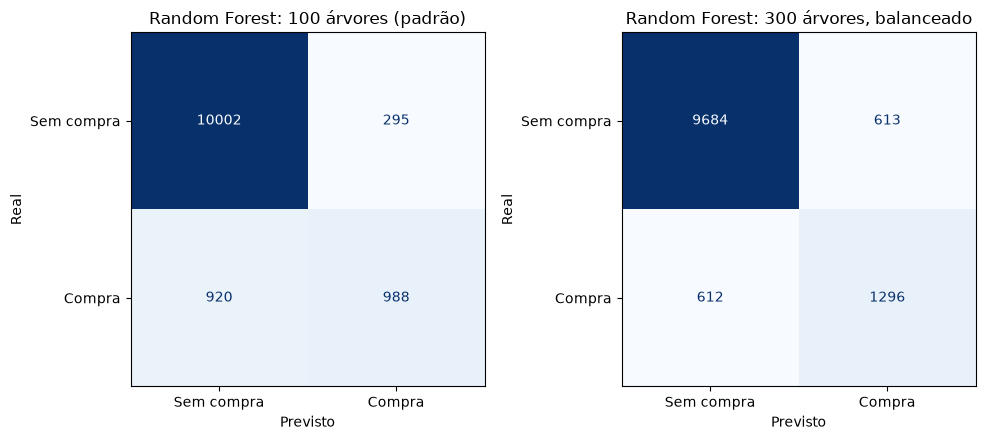

In [13]:
fig, eixos = plt.subplots(1, len(matrizes), figsize=(5 * len(matrizes), 4.5))
eixos = np.atleast_1d(eixos)

for eixo, (nome, matriz) in zip(eixos, matrizes.items()):
    ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=["Sem compra", "Compra"],
    ).plot(ax=eixo, cmap="Blues", colorbar=False, values_format="d")
    eixo.set_title(f"Random Forest: {nome}")
    eixo.set_xlabel("Previsto")
    eixo.set_ylabel("Real")

plt.tight_layout()
plt.savefig(saida / "matriz_confusao_random_forest.png", dpi=150)
plt.show()

## 7) Importância das variáveis

Este ajuste usa **todos** os dados e serve apenas para interpretação. As métricas do trabalho vêm da validação cruzada acima.

Top 10 variáveis mais importantes:


numericas__PageValues                 0.3862
numericas__ExitRates                  0.0830
numericas__ProductRelated_Duration    0.0796
numericas__ProductRelated             0.0657
numericas__BounceRates                0.0524
numericas__Administrative_Duration    0.0438
numericas__Administrative             0.0380
categoricas__Month_11                 0.0290
numericas__Informational_Duration     0.0191
numericas__Informational              0.0143
dtype: float64

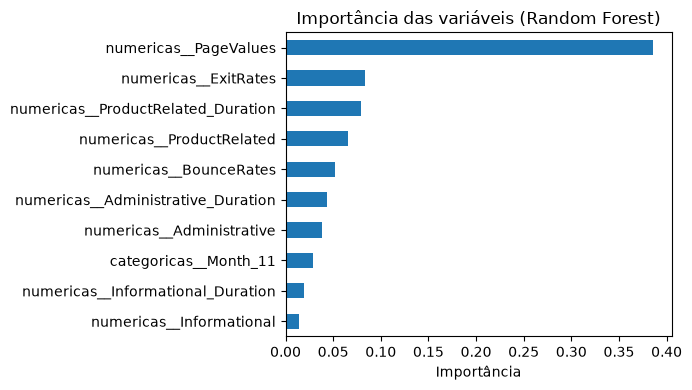

In [14]:
nome_final = list(configuracoes.keys())[-1]
modelo_final = Pipeline([
    ("preprocessamento", criar_preprocessador()),
    ("classificador", RandomForestClassifier(**configuracoes[nome_final])),
])
modelo_final.fit(X, y)

nomes = modelo_final.named_steps["preprocessamento"].get_feature_names_out()
importancias = pd.Series(
    modelo_final.named_steps["classificador"].feature_importances_,
    index=nomes,
).sort_values(ascending=False)

print("Top 10 variáveis mais importantes:")
display(importancias.head(10).round(4))

importancias.head(10)[::-1].plot(kind="barh", figsize=(7, 4))
plt.title("Importância das variáveis (Random Forest)")
plt.xlabel("Importância")
plt.tight_layout()
plt.savefig(saida / "importancia_variaveis_random_forest.png", dpi=150)
plt.show()